# Aula: otimizando um pedaço de DNA com um AED montado pelo DAMICORE

Este caderno explica, do zero, tudo o que fizemos com a enzima DHFR. Cada ideia
vem com o código que a mostra no dado real, então dá para rodar célula por célula
e ver os números aparecerem.

**Roteiro**

1. A biologia em poucas linhas: DNA, códon, proteína, enzima, antibiótico.
2. O dado de Papkou et al. (2023): o que foi medido e como ler o número.
3. Paisagem de aptidão e epistasia, vistas no dado.
4. O problema de otimização e por que um AED precisa de um bom modelo.
5. O DAMICORE por dentro, com uma geração de verdade: arquivos, NCD, árvore, grupos.
6. Do grupo ao modelo e aos filhos.
7. Uma busca inteira.
8. Os resultados das 30 buscas: otimiza?
9. O DAMICORE achou os códons?
10. Bate com a epistasia real?
11. Conclusões, limites, glossário e perguntas para fixar.

No fim de cada parte há um **resumo** de duas ou três linhas. Se só der tempo de
ler os resumos, já dá para explicar o trabalho.


In [1]:
from itertools import combinations
from pathlib import Path
import json
import sys
import tempfile
import zlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import toytree
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while (
    PROJECT_ROOT != PROJECT_ROOT.parent
    and not (PROJECT_ROOT / "pyproject.toml").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise RuntimeError("Open this notebook from the repository environment.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from hypotheses.dhfr_codon_linkage.scripts.config import ARTIFACT_ROOT, DATA_PATH, DEFAULT_CONFIG
from hypotheses.dhfr_codon_linkage.scripts.experiment import CODONS, _codon_contrast, _triple_partitions
from hypotheses.dhfr_codon_linkage.scripts.landscape import BASES, decode, load_landscape, pair_epistasis
from hypotheses.dhfr_codon_linkage.scripts.search import (
    Laboratory,
    damicore_groups,
    position_series,
    run_search,
    sample_offspring,
)

CODON_COLORS = ["#2B6CB0", "#D97A1E", "#2F8F6B"]
landscape = load_landscape()
solutions, fitness = landscape.table()


def draw_codon_boxes(ax):
    for c, color in enumerate(CODON_COLORS):
        ax.add_patch(plt.Rectangle((3 * c - 0.5, 3 * c - 0.5), 3, 3, fill=False, lw=2.5, ec=color))


/Users/erickpatrickbarcelos/codes/data-mining/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. A biologia em poucas linhas

**DNA é um texto de 4 letras.** As letras (bases) são A, C, G e T. Um **gene** é
um trecho desse texto que a célula usa como receita para fazer uma **proteína**.

**A célula lê de 3 em 3.** Cada trinca de letras é um **códon**, e cada códon diz
qual **aminoácido** entra na proteína (ou onde a leitura para). Como há 4³ = 64
códons e só 20 aminoácidos (mais o "pare"), vários códons dizem a mesma coisa:
GCC, GCA, GCG e GCT são todos alanina. Isso se chama **código redundante**.

**Proteína é uma corrente de aminoácidos.** A ordem dos aminoácidos decide a forma
da proteína, e a forma decide o que ela faz.

**Enzima é uma proteína que acelera uma reação.** A **DHFR** (di-hidrofolato
redutase) transforma di-hidrofolato em tetra-hidrofolato. A célula precisa disso
para fabricar as peças do DNA. Sem DHFR funcionando, a bactéria não copia o DNA
e não se divide.

**O antibiótico.** A **trimetoprima** gruda na DHFR das bactérias e trava a
enzima. A bactéria fica **resistente** quando uma mutação na DHFR faz o remédio
grudar menos, mas a enzima continua funcionando.

**O experimento de Papkou et al. (2023, *Science*).** Eles pegaram 3 códons
seguidos da DHFR da *E. coli* (os códons 26, 27 e 28, perto de onde a reação
acontece), ou seja, **9 letras**. Fizeram **todas** as 4⁹ = 262.144 versões
dessas 9 letras, cultivaram as bactérias juntas com trimetoprima e contaram, por
sequenciamento, quanto cada versão cresceu.

Abaixo, o código genético e a tradução da versão original e da melhor versão.


In [2]:
# Tabela padrão do código genético, na ordem T, C, A, G de cada letra do códon.
TABLE_ORDER = "TCAG"
AMINO = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
GENETIC_CODE = {
    a + b + c: AMINO[16 * i + 4 * j + k]
    for i, a in enumerate(TABLE_ORDER)
    for j, b in enumerate(TABLE_ORDER)
    for k, c in enumerate(TABLE_ORDER)
}
NAMES = {
    "A": "alanina", "R": "arginina", "N": "asparagina", "D": "aspartato", "C": "cisteína",
    "E": "glutamato", "Q": "glutamina", "G": "glicina", "H": "histidina", "I": "isoleucina",
    "L": "leucina", "K": "lisina", "M": "metionina", "F": "fenilalanina", "P": "prolina",
    "S": "serina", "T": "treonina", "W": "triptofano", "Y": "tirosina", "V": "valina", "*": "PARE",
}


def translate(sequence: str) -> str:
    return "".join(GENETIC_CODE[sequence[i : i + 3]] for i in (0, 3, 6))


def explain(sequence: str) -> str:
    codons = [sequence[i : i + 3] for i in (0, 3, 6)]
    return "  ".join(f"{c} → {NAMES[GENETIC_CODE[c]]}" for c in codons)


by_sequence = pd.Series(fitness, index=[decode(s) for s in solutions])
wild_type = "GCCGATCTC"
best = by_sequence.idxmax()
print(f"Original  {wild_type}: {explain(wild_type)}   fitness {by_sequence[wild_type]:.3f}")
print(f"Melhor    {best}: {explain(best)}   fitness {by_sequence[best]:.3f}")
print(f"Quantos códons dizem 'alanina'? {sum(v == 'A' for v in GENETIC_CODE.values())}")


Original  GCCGATCTC: GCC → alanina  GAT → aspartato  CTC → leucina   fitness 0.000
Melhor    AAGGAAATG: AAG → lisina  GAA → glutamato  ATG → metionina   fitness 1.396
Quantos códons dizem 'alanina'? 4


A original é **alanina – aspartato – leucina**. A melhor troca as três: vira
**lisina – glutamato – metionina**.

Agora a pergunta que importa para a aula: **o que decide o fitness, as letras ou
o aminoácido?** Se for o aminoácido, as 3 letras de um códon só fazem sentido
juntas, porque é a trinca inteira que escolhe o aminoácido. A célula abaixo agrupa
as sequências pela proteína que elas fazem e mede quanto da variação do fitness
a proteína explica.


In [3]:
alive = fitness > DEFAULT_CONFIG.alive_threshold
proteins = pd.Series([translate(decode(s)) for s in solutions[alive]])
values = pd.Series(fitness[alive])
group_mean = values.groupby(proteins.values).transform("mean")
explained = 1 - ((values - group_mean) ** 2).sum() / ((values - values.mean()) ** 2).sum()
print(f"Sequências que crescem (fitness > {DEFAULT_CONFIG.alive_threshold}): {alive.sum():,}")
print(f"Proteínas diferentes entre elas: {proteins.nunique():,}")
print(f"Parte da variação do fitness explicada só pela proteína: {explained:.0%}")

top = by_sequence.nlargest(15).rename("fitness").to_frame()
top["proteína"] = [translate(s) for s in top.index]
top["códons"] = [" ".join(s[i : i + 3] for i in (0, 3, 6)) for s in top.index]
display(top)
top70 = by_sequence.nlargest(DEFAULT_CONFIG.top_k)
print(f"As {DEFAULT_CONFIG.top_k} melhores sequências fazem só {pd.Series([translate(s) for s in top70.index]).nunique()} proteínas diferentes.")


Sequências que crescem (fitness > -0.5): 17,775
Proteínas diferentes entre elas: 1,630
Parte da variação do fitness explicada só pela proteína: 94%


,fitness,proteína,códons
AAGGAAATG,1.395792,KEM,AAG GAA ATG
CTGGAAATG,1.371104,LEM,CTG GAA ATG
CTGGAGATG,1.370810,LEM,CTG GAG ATG
AGGGAGATG,1.358285,REM,AGG GAG ATG
TCCGAAATG,1.356266,SEM,TCC GAA ATG
CAAGAAATG,1.356194,QEM,CAA GAA ATG
ACTGACCAG,1.352514,TDQ,ACT GAC CAG
TTGGAAATG,1.352293,LEM,TTG GAA ATG
GACGAAATG,1.351106,DEM,GAC GAA ATG
CGTGAAATG,1.349993,REM,CGT GAA ATG


As 70 melhores sequências fazem só 20 proteínas diferentes.


Veja na tabela: sequências diferentes que fazem a **mesma proteína** (mesma
coluna "proteína") têm fitness parecido. É a proteína que a bactéria "sente".
É por isso que esperamos que as letras de um mesmo códon **andem juntas**: trocar
uma letra sozinha muda o aminoácido para outro qualquer; o que dá certo é uma
trinca inteira bem escolhida.

> **Resumo da parte 1.** 9 letras de DNA = 3 códons = 3 aminoácidos da enzima
> DHFR. O antibiótico trava a DHFR; algumas versões da enzima resistem. O fitness
> depende muito da proteína, então as letras de um mesmo códon deveriam andar
> juntas. **Ninguém conta isso ao DAMICORE**: a pergunta é se ele descobre sozinho.


## 2. O dado

O arquivo `data/papkou2023_dhfr_fitness.csv.gz` (Zenodo 10.5281/zenodo.8228920,
licença CC BY 4.0) tem uma linha por sequência:

- `sequence`: as 9 letras;
- `fitness`: quanto a bactéria cresce com o antibiótico, **comparada com a
  original** e em escala logarítmica. 0 = igual à original; positivo = melhor;
  muito negativo = morre;
- `fitness_se`: o erro da medida.

Das 262.144 sequências possíveis, 261.333 têm medida. As 811 que faltam contam
como mortas (recebem o pior fitness medido).


,sequence,fitness,fitness_se
0,GCCGATCTC,0.000000,NaN
1,AAAAAAAAA,-0.733843,0.021081
2,AAAAAAAAC,-0.656973,0.020763
3,AAAAAAAAG,-0.701521,0.020317
4,AAAAAAAAT,-0.708582,0.017354


Linhas: 261,333 de 262,144 possíveis
Original: 0.  Melhor: 1.396.  Mediana: -0.71
Para estar entre as 70 melhores (0,03%) é preciso fitness ≥ 1.301


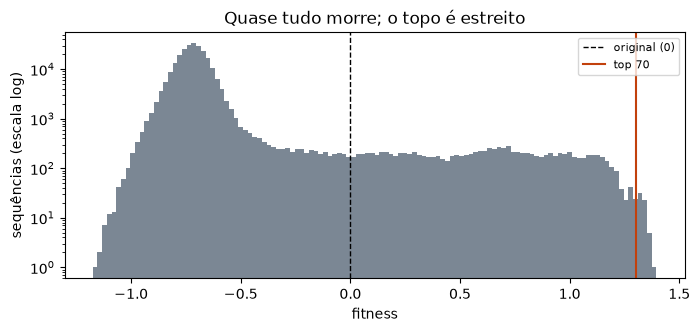

Sequências que crescem (fitness > -0.5): 17,775


In [4]:
raw = pd.read_csv(DATA_PATH)
display(raw.head())
print(f"Linhas: {len(raw):,} de {4 ** 9:,} possíveis")
print(f"Original: 0.  Melhor: {fitness.max():.3f}.  Mediana: {np.median(fitness):.2f}")
top_threshold = landscape.top_threshold(DEFAULT_CONFIG.top_k)
print(f"Para estar entre as {DEFAULT_CONFIG.top_k} melhores (0,03%) é preciso fitness ≥ {top_threshold:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(fitness, bins=120, color="#7B8794")
ax.axvline(0, color="black", lw=1, ls="--", label="original (0)")
ax.axvline(top_threshold, color="#C2410C", lw=1.5, label=f"top {DEFAULT_CONFIG.top_k}")
ax.set_yscale("log")
ax.set(xlabel="fitness", ylabel="sequências (escala log)", title="Quase tudo morre; o topo é estreito")
ax.legend(fontsize=8)
plt.show()
print(f"Sequências que crescem (fitness > {DEFAULT_CONFIG.alive_threshold}): {(fitness > DEFAULT_CONFIG.alive_threshold).sum():,}")


O eixo vertical está em escala log, senão a cauda some. Quase todas as sequências
estão no morro da esquerda, perto de −0,7: são bactérias que **morrem** com o
antibiótico. Só umas 18 mil crescem, e elas formam a cauda para a direita. Lá na
ponta, depois da linha vermelha, está o top 70: é ali que queremos chegar.

> **Resumo da parte 2.** Temos o fitness medido de quase todas as 262.144
> sequências. Isso é raro e valioso: sabemos **qual é a resposta certa**, então dá
> para conferir se o algoritmo chegou lá.


## 3. Paisagem de aptidão e epistasia

**Paisagem de aptidão.** Imagine cada sequência como um ponto num terreno e o
fitness como a altura. Duas sequências são **vizinhas** se diferem em uma letra
só; cada sequência tem 9 × 3 = 27 vizinhas. Otimizar é procurar o pico mais alto.

Um **pico local** é uma sequência melhor que todas as 27 vizinhas. Se houver muitos
picos, um algoritmo que só sobe pode ficar preso num pico baixo. Vamos contar os
picos no dado.


In [5]:
index = np.arange(4 ** 9)
best_neighbour = np.full(4 ** 9, -np.inf)
for position in range(9):
    weight = 4 ** (8 - position)
    base = (index // weight) % 4
    for shift in (1, 2, 3):
        neighbour = index + (((base + shift) % 4) - base) * weight
        best_neighbour = np.maximum(best_neighbour, landscape.fitness[neighbour])

peaks = landscape.measured & (landscape.fitness > best_neighbour)
alive_peaks = peaks & (landscape.fitness > DEFAULT_CONFIG.alive_threshold)
print(f"Picos locais (melhores que as 27 vizinhas): {peaks.sum():,}")
print(f"... entre as sequências que crescem: {alive_peaks.sum():,}")
print(f"O pico mais alto é {decode((index[landscape.fitness.argmax()] // 4 ** np.arange(8, -1, -1)) % 4)}")


Picos locais (melhores que as 27 vizinhas): 4,055
... entre as sequências que crescem: 479
O pico mais alto é AAGGAAATG


Há muitos picos: a paisagem é **acidentada**. Por que? Por causa da **epistasia**.

**Epistasia** é quando o efeito de trocar uma letra **depende** das outras letras.
Sem epistasia, cada posição teria sua letra boa e bastava escolher a melhor de
cada uma, separadamente. Com epistasia, a melhor letra da posição 7 depende do
que está na posição 8.

Veja no dado: fixamos as outras 7 posições como na melhor sequência e variamos só
as posições 7 e 8 (as 16 combinações).


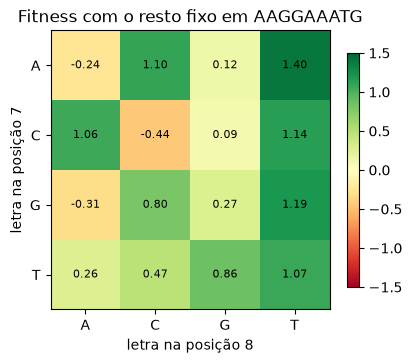

In [6]:
def pair_table(i: int, j: int, background: str) -> pd.DataFrame:
    table = pd.DataFrame(index=list(BASES), columns=list(BASES), dtype=float)
    for a in BASES:
        for b in BASES:
            sequence = list(background)
            sequence[i], sequence[j] = a, b
            table.loc[a, b] = by_sequence.get("".join(sequence), landscape.dead)
    table.index.name, table.columns.name = f"posição {i + 1}", f"posição {j + 1}"
    return table


table_78 = pair_table(6, 7, best)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
image = ax.imshow(table_78, cmap="RdYlGn", vmin=-1.5, vmax=1.5)
ax.set_xticks(range(4), list(BASES))
ax.set_yticks(range(4), list(BASES))
ax.set(xlabel="letra na posição 8", ylabel="letra na posição 7",
       title=f"Fitness com o resto fixo em {best}")
for (r, c), value in np.ndenumerate(table_78.to_numpy()):
    ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()


Compare as linhas A e C. Com **A** na posição 7, trocar a posição 8 de A para C
**sobe** o fitness de −0,24 para 1,10. Com **C** na posição 7, a mesma troca
**derruba** de 1,06 para −0,44. A mesma mudança é ótima ou péssima dependendo do
vizinho. Se não houvesse epistasia, as linhas seriam "paralelas": trocar a
posição 8 mudaria o fitness do mesmo tanto em qualquer linha.

**Medindo a epistasia de todos os pares.** A função `pair_epistasis` faz isso com
as 261 mil medidas:

1. Ajusta um **modelo aditivo**: cada letra em cada posição soma um valor fixo,
   sem interação nenhuma.
2. Guarda o que esse modelo **não** explica (os resíduos).
3. Para cada par (i, j), vê quanto dos resíduos é explicado pelas 16 combinações
   de letras desse par. Essa fração é a epistasia do par.

Só usamos as sequências que crescem: entre as mortas, todo mundo parece igual.
**Importante:** o AED nunca vê esta tabela. Ela é o gabarito para conferir no fim.


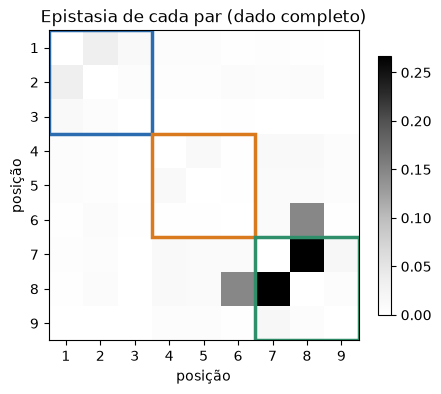

Pares mais fortes: 7-8 = 0.267, 6-8 = 0.147, 1-2 = 0.035, 7-9 = 0.018, 4-8 = 0.013


In [7]:
epistasis = pair_epistasis(landscape, DEFAULT_CONFIG.alive_threshold)
fig, ax = plt.subplots(figsize=(5, 4.2))
image = ax.imshow(epistasis, cmap="Greys")
ax.set_xticks(range(9), range(1, 10))
ax.set_yticks(range(9), range(1, 10))
draw_codon_boxes(ax)
ax.set(title="Epistasia de cada par (dado completo)", xlabel="posição", ylabel="posição")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()
strongest = [
    (f"{i + 1}-{j + 1}", epistasis.iat[i, j]) for i, j in combinations(range(9), 2)
]
print("Pares mais fortes:", ", ".join(f"{p} = {v:.3f}" for p, v in sorted(strongest, key=lambda x: -x[1])[:5]))


O par 7-8 é de longe o mais forte, seguido de 6-8. Os quadrados coloridos são os
códons: a interação forte fica mais dentro do terceiro códon, mas não é só
"códon = interação" (6-8 cruza a fronteira entre o segundo e o terceiro).

> **Resumo da parte 3.** A paisagem tem muitos picos porque há epistasia: o
> efeito de uma letra depende de outras. O par 7-8 é o que mais interage. Um
> algoritmo que escolhe cada posição sozinha vai sofrer com isso.


## 4. O problema de otimização

**Objetivo:** achar uma sequência com fitness alto **medindo o mínimo possível**.
Num laboratório, cada medida custa tempo e dinheiro. Damos ao algoritmo
**1.000 medidas** por busca: 0,4% das 262.144.

Para ter noção do tamanho do problema: sorteando ao acaso, quantas sequências
precisaríamos medir, em média, para cair uma vez no top 70?


In [8]:
share_top = DEFAULT_CONFIG.top_k / 4 ** 9
print(f"Chance de uma sequência sorteada estar no top 70: {share_top:.4%}")
print(f"Medidas esperadas até a primeira: {1 / share_top:,.0f}")
print(f"Chance de cair no top 70 em {DEFAULT_CONFIG.budget} sorteios: {1 - (1 - share_top) ** DEFAULT_CONFIG.budget:.0%}")


Chance de uma sequência sorteada estar no top 70: 0.0267%
Medidas esperadas até a primeira: 3,745
Chance de cair no top 70 em 1000 sorteios: 23%


**Algoritmos evolutivos.** Mantêm uma **população** de soluções, **selecionam**
as melhores e geram **filhos** a partir delas, repetindo. No algoritmo genético
clássico, os filhos saem de cruzamento e mutação.

**AED (algoritmo de estimação de distribuição).** Troca cruzamento e mutação por
um **modelo de probabilidade**: olha as soluções promissoras, aprende "como elas
costumam ser" e sorteia filhos parecidos.

O modelo mais simples sorteia **cada posição sozinha**, com a frequência de cada
letra entre as promissoras. Isso quebra combinações boas. Veja no dado: pegamos
as 300 melhores sequências e olhamos o par 7-8.


In [9]:
best_300 = solutions[np.argsort(-fitness)[:300]]
pairs_78 = pd.Series([BASES[a] + BASES[b] for a, b in best_300[:, 6:8]])
joint = pairs_78.value_counts(normalize=True)
p7 = pd.Series([BASES[a] for a in best_300[:, 6]]).value_counts(normalize=True)
p8 = pd.Series([BASES[b] for b in best_300[:, 7]]).value_counts(normalize=True)
independent = pd.Series({a + b: p7[a] * p8[b] for a in p7.index for b in p8.index})

compare = pd.DataFrame({"visto nas 300 melhores": joint, "sorteando cada posição sozinha": independent}).fillna(0)
compare = compare.sort_values("sorteando cada posição sozinha", ascending=False).head(8)
display((100 * compare).round(1).astype(str) + " %")
never_seen = independent[~independent.index.isin(joint.index)].sum()
print(f"Sorteando cada posição sozinha, {never_seen:.0%} dos filhos teriam em 7-8 um par que nenhuma das 300 melhores tem.")


,visto nas 300 melhores,sorteando cada posição sozinha
AT,32.0 %,25.2 %
CT,13.0 %,23.1 %
GT,15.7 %,10.1 %
AA,0.0 %,9.5 %
CA,23.7 %,8.7 %
TT,2.3 %,4.6 %
GA,0.0 %,3.8 %
AC,6.3 %,3.6 %


Sorteando cada posição sozinha, 21% dos filhos teriam em 7-8 um par que nenhuma das 300 melhores tem.


Sorteando separado, uma boa parte dos filhos sai com combinações em 7-8 que
**nenhuma** sequência boa tem. A saída é sortear **o par inteiro** de uma tabela
conjunta: "entre as promissoras, 7-8 foi AT tantas vezes, GC tantas vezes...".
Assim combinações boas não se quebram.

Mas aí vem o problema: **quais posições devem ser sorteadas juntas?** Num problema
real ninguém sabe. É exatamente isso que o slide "DAMICORE gerando modelos para
AEDs" propõe: o DAMICORE olha as promissoras e diz quais posições andam juntas.

> **Resumo da parte 4.** Queremos o topo medindo 0,4% das sequências. O AED
> aprende um modelo das boas soluções; se o modelo separa posições que interagem,
> ele quebra combinações boas. O DAMICORE é quem decide o agrupamento.


## 5. O DAMICORE por dentro, com uma geração de verdade

O DAMICORE recebe **objetos** (arquivos) e devolve **grupos** de objetos parecidos,
em três passos:

1. **NCD**: distância entre cada par de arquivos, medida por compressão.
2. **Neighbor Joining**: transforma a matriz de distâncias numa árvore.
3. **FastGreedy**: corta a árvore em grupos (comunidades).

Ele não sabe nada de DNA. Só compara arquivos. Vamos fazer uma geração inteira na
mão, com a semente 1: sortear 200 sequências, medir, pegar as 30% melhores (60).


In [10]:
rng = np.random.default_rng([1, DEFAULT_CONFIG.budget, 11])
lab = Laboratory(landscape, DEFAULT_CONFIG.budget)
population = rng.integers(0, 4, (DEFAULT_CONFIG.population_size, 9))
population_fitness = lab(population)
selected = int(round(DEFAULT_CONFIG.selection_fraction * DEFAULT_CONFIG.population_size))
promising = population[np.argsort(-population_fitness, kind="stable")[:selected]]

print(f"Medidas gastas: {len(lab.measured)}.  Promissoras: {len(promising)}")
print(f"Melhor da população inicial: {population_fitness.max():.3f}")
display(pd.DataFrame({
    "id": range(6),
    "sequência": [decode(s) for s in promising[:6]],
    "fitness": np.sort(population_fitness)[::-1][:6].round(3),
}))


Medidas gastas: 200.  Promissoras: 60
Melhor da população inicial: 0.858


,id,sequência,fitness
0,0,CTAGATGCA,0.858
1,1,TGTGACAGG,0.758
2,2,AATGATAGA,0.726
3,3,CGCGAGGCA,0.653
4,4,GACGACGCT,0.492
5,5,GAGGACCGT,0.491


### Passo A: um arquivo por posição

Os objetos que queremos agrupar são as **9 posições**, não as sequências. Então
cada posição vira um arquivo de texto.

Cada promissora ganha um **id** (0, 1, 2, ...). O arquivo da posição 7 lista: os
ids das promissoras que têm **A** na posição 7, depois as que têm **C**, depois
**G**, depois **T**, separados por `|`.

A ideia: se as posições 7 e 8 andam juntas (por exemplo, toda sequência com A na
7 tem T na 8), os dois arquivos vão listar **os mesmos ids juntos**, só que debaixo
de letras diferentes. O nome da letra não importa; importa quais sequências ficam
juntas.


In [11]:
def readable(position: int) -> str:
    column = promising[:, position]
    return " | ".join(
        f"{BASES[b]}: " + " ".join(str(i) for i in np.flatnonzero(column == b)[:8])
        + (" ..." if (column == b).sum() > 8 else "")
        for b in range(4)
    )


for position in (6, 7, 8):
    print(f"posição {position + 1} -> {readable(position)}")

series = position_series(promising)
print()
print("O arquivo de verdade da posição 7 (primeiros 60 bytes):", series[6][:60])
print("Tamanho de cada arquivo (bytes):", [len(s) for s in series])


posição 7 -> A: 1 2 9 12 16 17 22 24 ... | C: 5 6 7 8 10 11 14 15 ... | G: 0 3 4 26 32 33 35 | T: 13 18 19 23 27 30 38 42 ...
posição 8 -> A: 12 24 37 40 41 45 47 48 ... | C: 0 3 4 8 9 11 13 16 ... | G: 1 2 5 6 7 10 18 27 ... | T: 14 15 20 23 29 30 32 33 ...
posição 9 -> A: 0 2 3 7 11 18 20 23 ... | C: 9 13 17 19 22 26 29 37 ... | G: 1 6 8 12 14 15 21 25 ... | T: 4 5 10 16 31 34 39 46 ...

O arquivo de verdade da posição 7 (primeiros 60 bytes): b'!!"!!#!!*!!-!!1!!2!!7!!9!!=!!>!!@!!E!!F!!H!!I!!J!!O!!S!!T!!['
Tamanho de cada arquivo (bytes): [184, 184, 184, 184, 184, 184, 184, 184, 184]


No arquivo de verdade, cada id vira **3 caracteres** (por exemplo `!!!`, `!!"`).
Por que 3? Porque o **zlib** (o compressor) só reconhece repetições de 3 bytes ou
mais. Com ids de 1 byte, ele não conseguiria perceber que dois arquivos repetem a
mesma sequência de ids.

### Passo B: NCD, a distância por compressão

Um compressor encontra **repetições** e as troca por referências curtas. Se dois
arquivos têm muito em comum, comprimir os dois **juntos** custa quase o mesmo que
comprimir só um. Daí a fórmula:

$$\mathrm{NCD}(x, y) = \frac{C(xy) - \min(C(x), C(y))}{\max(C(x), C(y))}$$

onde $C(x)$ é o tamanho de $x$ comprimido e $xy$ é um arquivo colado no outro.
Perto de 0 = quase iguais; perto de 1 = nada em comum.

Fazemos a conta à mão com o zlib para ver a ideia funcionando.


In [12]:
def compressed(data: bytes) -> int:
    return len(zlib.compress(data, 6))


def ncd(x: bytes, y: bytes) -> float:
    cx, cy = compressed(x), compressed(y)
    return (compressed(x + y) - min(cx, cy)) / max(cx, cy)


for i, j in ((6, 7), (6, 8), (0, 1), (0, 8)):
    x, y = series[i], series[j]
    print(f"p{i + 1} e p{j + 1}: C(x)={compressed(x)}  C(y)={compressed(y)}  C(xy)={compressed(x + y)}  NCD={ncd(x, y):.3f}")

manual = pd.DataFrame(
    [[ncd(a, b) if a is not b else 0.0 for b in series] for a in series],
    index=[f"p{p}" for p in range(1, 10)], columns=[f"p{p}" for p in range(1, 10)],
)
display(manual.round(2))


p7 e p8: C(x)=101  C(y)=99  C(xy)=182  NCD=0.822
p7 e p9: C(x)=101  C(y)=98  C(xy)=190  NCD=0.911
p1 e p2: C(x)=100  C(y)=100  C(xy)=183  NCD=0.830
p1 e p9: C(x)=100  C(y)=98  C(xy)=185  NCD=0.870


,p1,p2,p3,p4,p5,p6,p7,p8,p9
p1,0.00,0.83,0.87,0.86,0.86,0.88,0.85,0.91,0.87
p2,0.83,0.00,0.87,0.89,0.90,0.85,0.89,0.88,0.92
p3,0.85,0.86,0.00,0.87,0.87,0.89,0.86,0.92,0.91
p4,0.88,0.88,0.89,0.00,0.79,0.86,0.84,0.91,0.92
p5,0.85,0.90,0.90,0.81,0.00,0.89,0.85,0.90,0.93
p6,0.88,0.87,0.87,0.88,0.88,0.00,0.86,0.91,0.86
p7,0.89,0.88,0.89,0.85,0.87,0.87,0.00,0.82,0.91
p8,0.86,0.91,0.90,0.91,0.88,0.90,0.79,0.00,0.88
p9,0.87,0.92,0.93,0.92,0.95,0.90,0.88,0.93,0.00


Os números ficam todos perto de 0,8–0,9: com 60 promissoras os arquivos são
curtos e o compressor tem pouco com o que trabalhar. O que importa é a
**ordem**: pares que andam juntos ficam um pouco mais perto que os outros (7-8
dá 0,82, enquanto 7-9 dá 0,91).

A tabela à mão não é exatamente simétrica: comprimir x colado em y não dá
exatamente o mesmo tamanho que y colado em x. O DAMICORE cuida disso na sua
própria implementação.

### Passo C: Neighbor Joining, a árvore

Com a matriz 9 × 9, o Neighbor Joining (Saitou e Nei, 1987) monta uma árvore:

1. Calcula para cada par um número $Q(i, j)$ que mede "estes dois estão mais
   perto entre si do que do resto".
2. Junta o par com menor $Q$ num nó novo.
3. Recalcula as distâncias do nó novo para os outros.
4. Repete até sobrar uma árvore só.

Posições parecidas acabam em galhos vizinhos.

### Passo D: FastGreedy, os grupos

A árvore é tratada como uma rede, e o FastGreedy (Clauset, Newman e Moore, 2004)
procura uma divisão com **modularidade** alta: muitas ligações dentro dos grupos e
poucas entre eles. Ele começa com cada nó sozinho e vai unindo, sempre a união que
mais aumenta a modularidade. Cada grupo final vira uma tabela do modelo do AED.

Agora rodamos o DAMICORE de verdade sobre esses 9 arquivos.


Grupos do DAMICORE: [[1, 2], [3], [4, 5], [6, 9], [7, 8]]
Diagnóstico: {'damicore_status': 'ok', 'constant_positions': 0, 'group_count': 5, 'largest_group': 2}


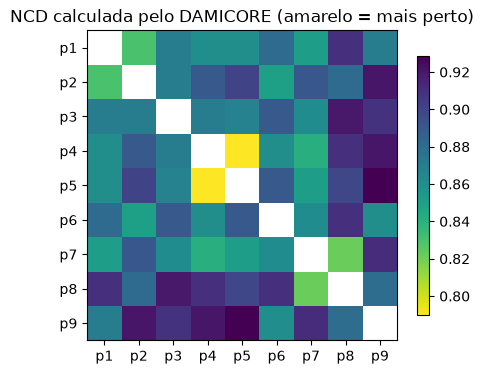

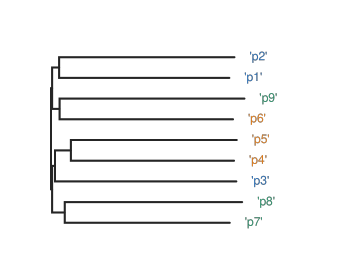

In [13]:
keep_dir = Path(tempfile.mkdtemp(prefix="aula-dhfr-"))
groups, diagnostics = damicore_groups(promising, keep_dir)
print("Grupos do DAMICORE:", [[p + 1 for p in g] for g in groups])
print("Diagnóstico:", diagnostics)

damicore_ncd = pd.read_csv(keep_dir / "ncd_matrix.csv", index_col=0)
fig, ax = plt.subplots(figsize=(5, 4.2))
off_diagonal = damicore_ncd.where(~np.eye(len(damicore_ncd), dtype=bool))
image = ax.imshow(off_diagonal, cmap="viridis_r")
ax.set_xticks(range(len(damicore_ncd)), damicore_ncd.columns)
ax.set_yticks(range(len(damicore_ncd)), damicore_ncd.index)
ax.set_title("NCD calculada pelo DAMICORE (amarelo = mais perto)")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

codon_of = {f"p{p + 1}": c for c, members in enumerate(CODONS) for p in members}
tree = toytree.tree((keep_dir / "tree.nwk").read_text(encoding="utf-8"))
colors = [CODON_COLORS[codon_of[name.strip("'")]] for name in tree.get_tip_labels()]
canvas, _, _ = tree.draw(width=360, height=280, tip_labels_colors=colors)
display(canvas)


Na árvore, cada posição está pintada com a cor do seu códon verdadeiro (azul =
1-2-3, laranja = 4-5-6, verde = 7-8-9). Cores iguais lado a lado = o DAMICORE
"viu" o códon nesta geração. A matriz do DAMICORE pode diferir um pouco da nossa
conta à mão, porque ele tem sua própria implementação, mas a ideia é a mesma.

**Casos especiais no código (`damicore_groups`):**

- Uma posição em que todas as promissoras têm a mesma letra é **constante**: não
  há o que relacionar, ela fica sozinha.
- Arquivos idênticos carregam a mesma informação: um vai para o DAMICORE e os
  outros entram no grupo dele.
- Se o FastGreedy juntar tudo num grupo só, isso não diz nada; cada posição fica
  sozinha.

> **Resumo da parte 5.** Cada posição vira um arquivo com os ids das promissoras
> separados por letra. O zlib mede quanto dois arquivos se repetem (NCD), o
> Neighbor Joining faz a árvore e o FastGreedy corta em grupos. Nada disso sabe
> o que é DNA.


## 6. Do grupo ao modelo e aos filhos

Para cada grupo, o modelo é uma **tabela**: as combinações de letras que
aparecem nas promissoras naquelas posições, com a frequência de cada uma. Um
grupo de 3 posições tem até 64 combinações possíveis, mas a tabela só guarda as
que apareceram.


In [14]:
for group in groups:
    columns = list(group)
    patterns, counts = np.unique(promising[:, columns], axis=0, return_counts=True)
    order = np.argsort(-counts)
    shown = ", ".join(
        f"{''.join(BASES[v] for v in patterns[k])} {counts[k] / counts.sum():.0%}" for k in order[:6]
    )
    more = f" (+{len(patterns) - 6} outras)" if len(patterns) > 6 else ""
    print(f"grupo {[p + 1 for p in group]}: {shown}{more}")


grupo [1, 2]: AA 12%, AC 12%, CT 10%, GA 10%, CC 8%, CG 8% (+9 outras)
grupo [3]: T 30%, C 27%, G 27%, A 17%
grupo [4, 5]: GA 20%, AG 8%, AT 8%, GT 8%, TC 8%, CA 7% (+10 outras)
grupo [6, 9]: CA 13%, AA 8%, CC 8%, CG 8%, TA 8%, AC 7% (+10 outras)
grupo [7, 8]: AC 12%, CG 10%, AA 8%, AG 8%, CC 8%, TG 8% (+7 outras)


**Gerar um filho:** para cada grupo, sorteia uma linha da tabela (com a
frequência como chance) e copia aquelas letras. Juntando os grupos, sai uma
sequência de 9 letras.

**Quem sobrevive:** pais e filhos competem juntos e ficam os 200 melhores (isso se
chama seleção (μ+λ)). Sequência já medida não gasta orçamento: o laboratório só
consulta a medida antiga.


In [15]:
before = len(lab.measured)
offspring = sample_offspring(rng, promising, groups, DEFAULT_CONFIG.population_size)
offspring_fitness = lab(offspring)
print("Primeiros filhos:", [decode(s) for s in offspring[:5]])
print(f"Filhos novos medidos: {len(lab.measured) - before} de {len(offspring)}")
print(f"Melhor filho: {offspring_fitness.max():.3f}  (melhor pai era {population_fitness.max():.3f})")

merged = np.vstack([population, offspring])
merged_fitness = np.concatenate([population_fitness, offspring_fitness])
survivors = np.argsort(-merged_fitness, kind="stable")[: DEFAULT_CONFIG.population_size]
print(f"Média das 60 melhores: antes {np.sort(population_fitness)[-selected:].mean():.3f}, "
      f"depois {np.sort(merged_fitness[survivors])[-selected:].mean():.3f}")


Primeiros filhos: ['AAGGACACA', 'CATCTGTCC', 'GAATCACTC', 'GAGACTACG', 'AGCTTAACA']
Filhos novos medidos: 199 de 200
Melhor filho: 1.239  (melhor pai era 0.858)
Média das 60 melhores: antes -0.448, depois 0.168


> **Resumo da parte 6.** Cada grupo do DAMICORE vira uma tabela de combinações
> vistas nas promissoras. Os filhos sorteiam cada grupo inteiro, então combinações
> boas passam adiante. Os melhores entre pais e filhos seguem.


## 7. Uma busca inteira

A função `run_search` repete a geração da parte 5 e 6 até gastar as 1.000
medidas. Uma regra extra: se uma geração não mede **nada novo** (o modelo só
propõe sequências já medidas), metade da população é sorteada de novo, para a
busca continuar explorando.


In [16]:
result = run_search(landscape, seed=1)
history = pd.DataFrame(result.history)
display(history[["generation", "evaluations", "best_fitness", "mean_promising_fitness", "groups", "restarted"]].round(3))
print(f"Melhor achada: {result.best_sequence} ({translate(result.best_sequence)}), fitness {result.best_fitness:.3f}")
print(f"Isso é {result.best_fitness / landscape.optimum:.1%} do melhor possível ({best}, {landscape.optimum:.3f})")
print(f"Entrou no top 70 após {result.evaluations_to_top} medidas")


,generation,evaluations,best_fitness,mean_promising_fitness,groups,restarted
0,1,399,1.239,0.168,1-2 3 4-5 6-9 7-8,False
1,2,591,1.240,0.906,1-2-9 3-6 4-5 7-8,False
2,3,773,1.349,1.153,4 5 1-2 3 6-8 7-9,False
3,4,936,1.350,1.225,4 5 1-2 3-6 7-8-9,False
4,5,1000,1.350,1.274,4 5 1-2-3 6-8 7-9,False


Melhor achada: CGTGAAATG (REM), fitness 1.350
Isso é 96.7% do melhor possível (AAGGAAATG, 1.396)
Entrou no top 70 após 773 medidas


Como ler a tabela: `evaluations` é quantas sequências diferentes já foram medidas,
`best_fitness` a melhor até ali, `mean_promising_fitness` a média das 60 melhores
da população, e `groups` os grupos que o DAMICORE formou naquela geração (por
exemplo `7-8` quer dizer que 7 e 8 foram sorteadas juntas).

Repare que nas últimas gerações aparecem posições sozinhas (4 e 5 aqui): a
população já convergiu e todas as promissoras têm a mesma letra nelas (posições
constantes), então não há o que relacionar.

> **Resumo da parte 7.** Uma busca são umas 6 a 8 gerações, cada uma com uma
> chamada ao DAMICORE, até gastar 1.000 medidas.


## 8. Os resultados das 30 buscas: otimiza?

Rodamos 30 buscas, cada uma com uma semente diferente (um sorteio inicial
diferente). Os resultados ficam em `artifacts/<data>/`. Se não houver nenhum, a
célula roda o experimento (uns 20 segundos).


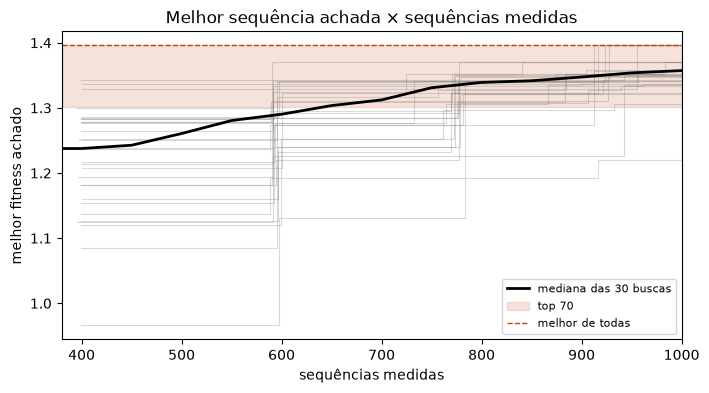

Buscas que chegaram ao top 70: 100%
Buscas que acharam a melhor de todas (AAGGAAATG): 27%
Em média, a melhor achada vale 97.6% do máximo
Mediana de medidas até entrar no top 70: 766


,seed,best_sequence,proteína,best_fitness,evaluations_to_top
0,1,CGTGAAATG,REM,1.350,773
1,2,ACTGACCAG,TDQ,1.353,589
2,3,AAGGAAATG,KEM,1.396,600
3,4,AAGGAAATG,KEM,1.396,732
4,5,CTGGAAATG,LEM,1.371,591
5,6,AAGGAAATG,KEM,1.396,400
6,7,CGTGAAATG,REM,1.350,772
7,8,ACTGACCAG,TDQ,1.353,776
8,9,GTCGACCAA,VDQ,1.337,764
9,10,TACGACCAA,YDQ,1.335,942


In [17]:
runs_dirs = sorted(p for p in ARTIFACT_ROOT.glob("*") if (p / "audit.json").exists())
if runs_dirs:
    output_dir = runs_dirs[-1]
else:
    from hypotheses.dhfr_codon_linkage.scripts.experiment import execute_experiment
    output_dir = execute_experiment().output_dir

audit = json.loads((output_dir / "audit.json").read_text(encoding="utf-8"))
runs = pd.read_csv(output_dir / "runs.csv")
generations = pd.read_csv(output_dir / "generations.csv")
frequency = pd.read_csv(output_dir / "pair_frequency.csv", index_col=0)
pairs = pd.read_csv(output_dir / "pairs.csv")

fig, ax = plt.subplots(figsize=(8, 4))
for _, run in generations.groupby("seed"):
    ax.step(run["evaluations"], run["best_fitness"], where="post", color="grey", alpha=0.3, lw=0.8)
grid = np.arange(200, DEFAULT_CONFIG.budget + 1, 50)
curves = [np.interp(grid, run["evaluations"], run["best_fitness"]) for _, run in generations.groupby("seed")]
ax.plot(grid, np.median(curves, axis=0), color="black", lw=2, label="mediana das 30 buscas")
ax.axhspan(audit["top_threshold"], audit["optimum"]["fitness"], color="#C2410C", alpha=0.15, label="top 70")
ax.axhline(audit["optimum"]["fitness"], color="#C2410C", lw=1, ls="--", label="melhor de todas")
ax.set(xlabel="sequências medidas", ylabel="melhor fitness achado", xlim=(380, DEFAULT_CONFIG.budget),
       title="Melhor sequência achada × sequências medidas")
ax.legend(fontsize=8)
plt.show()

print(f"Buscas que chegaram ao top 70: {audit['reached_top_share']:.0%}")
print(f"Buscas que acharam a melhor de todas ({audit['optimum']['sequence']}): {audit['found_optimum_share']:.0%}")
print(f"Em média, a melhor achada vale {audit['mean_share_of_optimum']:.1%} do máximo")
print(f"Mediana de medidas até entrar no top 70: {audit['median_evaluations_to_top']:.0f}")
runs["proteína"] = runs["best_sequence"].map(translate)
display(runs[["seed", "best_sequence", "proteína", "best_fitness", "evaluations_to_top"]].head(10).round(3))


Cada linha cinza é uma busca; a preta é a mediana. **Todas** as 30 chegaram ao top
70 (as 0,03% melhores) medindo 0,4% das sequências, e cerca de um quarto achou
exatamente a melhor de todas. Note também na coluna "proteína": buscas que não
acharam a melhor sequência muitas vezes acharam outra que faz uma proteína igual
ou parecida.

> **Resumo da parte 8.** Otimiza: 100% das buscas no top 70, 27% no ótimo, e a
> melhor achada vale em média 97,6% do máximo.


## 9. O DAMICORE achou os códons?

Para cada par de posições, contamos em que fração das gerações (de todas as 30
buscas) o DAMICORE colocou as duas no **mesmo grupo**. Os quadrados coloridos são
os códons. Se o DAMICORE enxerga códons, os números altos ficam dentro deles.


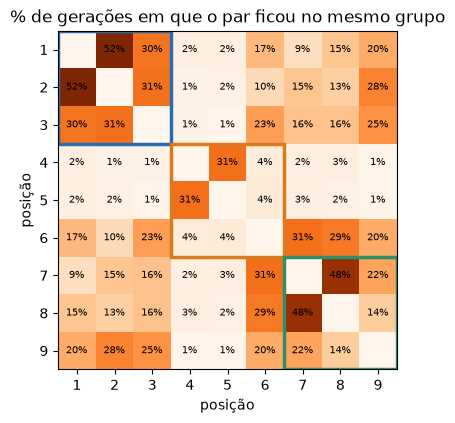

,pair,same_codon,grouped_share,epistasis
0,1-2,True,0.519,0.035
1,7-8,True,0.476,0.267
2,6-7,False,0.314,0.011
3,4-5,True,0.314,0.012
4,2-3,True,0.308,0.005
5,1-3,True,0.303,0.013
6,6-8,False,0.292,0.147
7,2-9,False,0.276,0.001


In [18]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
image = ax.imshow(frequency, cmap="Oranges", vmin=0)
ax.set_xticks(range(9), range(1, 10))
ax.set_yticks(range(9), range(1, 10))
for (r, c), value in np.ndenumerate(frequency.to_numpy()):
    if r != c:
        ax.text(c, r, f"{value:.0%}", ha="center", va="center", fontsize=7)
draw_codon_boxes(ax)
ax.set(title="% de gerações em que o par ficou no mesmo grupo", xlabel="posição", ylabel="posição")
plt.show()
display(pairs.head(8).round(3))


Os dois pares mais agrupados são **1-2** e **7-8**, ambos dentro de um códon; 4-5
também aparece alto.

**Teste: a divisão em códons é especial?** Existem 280 jeitos de dividir 9
posições em 3 trios (9! / (3!³ · 3!) = 280). Para cada divisão calculamos um
**contraste**: a média de "juntas" dos pares dentro dos trios menos a média dos
pares entre trios. Se o DAMICORE não visse nada de códon, a divisão em códons
cairia no meio da pilha.

O **valor-p** é a fração das 280 divisões com contraste igual ou maior que o dos
códons. Não precisa de nenhuma suposição estatística: é só contar.


Divisões possíveis: 280


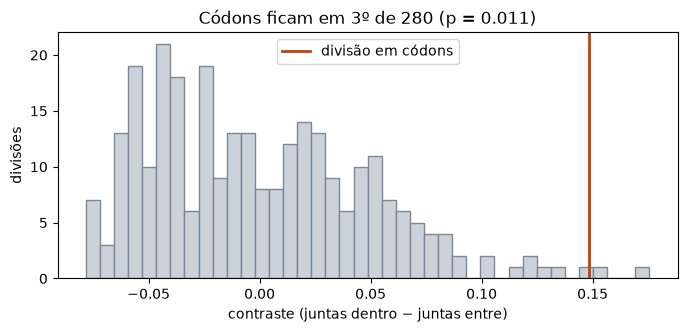

1º: 1-2-3 | 4-5-9 | 6-7-8   contraste 0.176
2º: 1-2-9 | 3-4-5 | 6-7-8   contraste 0.156
3º: 1-2-3 | 4-5-6 | 7-8-9   contraste 0.148


In [19]:
values = frequency.to_numpy()
partitions = _triple_partitions()
contrasts = np.array([_codon_contrast(values, p) for p in partitions])
test = audit["codon_test"]
print(f"Divisões possíveis: {len(partitions)}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(contrasts, bins=40, color="#CBD2D9", edgecolor="#7B8794")
ax.axvline(test["codon_contrast"], color="#C2410C", lw=2, label="divisão em códons")
ax.set(xlabel="contraste (juntas dentro − juntas entre)", ylabel="divisões",
       title=f"Códons ficam em {test['codon_rank']}º de {test['partitions']} (p = {test['p_value']:.3f})")
ax.legend()
plt.show()
for rank, partition in enumerate(sorted(partitions, key=lambda p: -_codon_contrast(values, p))[:3], start=1):
    print(f"{rank}º: " + " | ".join("-".join(str(q + 1) for q in trio) for trio in partition)
          + f"   contraste {_codon_contrast(values, partition):.3f}")


A divisão em códons fica em **3º lugar de 280** (p ≈ 0,01). A melhor de todas,
1-2-3 | 4-5-9 | 6-7-8, é igual aos códons exceto por trocar as posições 6 e 9.

> **Resumo da parte 9.** Sem ninguém contar, o DAMICORE agrupa as posições de um
> mesmo códon muito mais do que o acaso explicaria.


## 10. Bate com a epistasia real?

Códon é a explicação biológica. Mas o dado mostra diretamente outra coisa: a
**epistasia** de cada par (parte 3), calculada com as 261 mil medidas. Será que os
pares que o DAMICORE mais junta são os que mais interagem de verdade?

Usamos a **correlação de Spearman**: ela compara as **ordens** (o par que mais
interage é o que mais é agrupado?), sem supor nenhuma reta. Vai de −1 a 1.


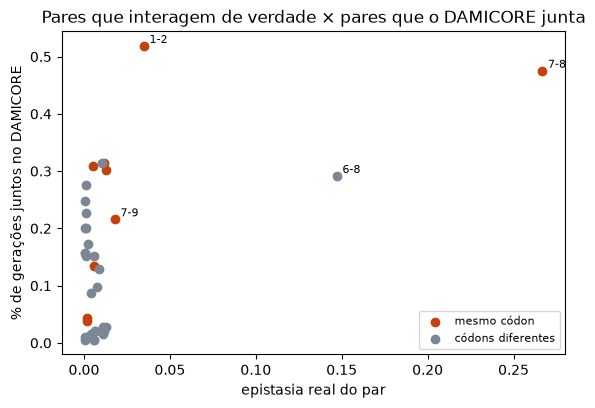

Spearman nos 36 pares: 0.22 (p = 0.19)


In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for same, color, label in ((True, "#C2410C", "mesmo códon"), (False, "#7B8794", "códons diferentes")):
    part = pairs.loc[pairs["same_codon"] == same]
    ax.scatter(part["epistasis"], part["grouped_share"], color=color, label=label)
for _, row in pairs.sort_values("epistasis", ascending=False).head(4).iterrows():
    ax.annotate(row["pair"], (row["epistasis"], row["grouped_share"]), fontsize=8,
                xytext=(4, 2), textcoords="offset points")
ax.set(xlabel="epistasia real do par", ylabel="% de gerações juntos no DAMICORE",
       title="Pares que interagem de verdade × pares que o DAMICORE junta")
ax.legend(fontsize=8)
plt.show()
spearman = audit["grouped_share_vs_epistasis_spearman"]
print(f"Spearman nos 36 pares: {spearman['rho']:.2f} (p = {spearman['p_value']:.2f})")


O par mais forte de verdade (7-8) está entre os dois que o DAMICORE mais junta, e
o segundo (6-8) também aparece alto. Mas no geral a correlação é **fraca e não
significativa** (ρ = 0,22): o DAMICORE também junta pares sem interação nenhuma.

> **Resumo da parte 10.** Acerta os pares fortes, mas erra vários fracos.


## 11. Conclusões e limites

**O que dá para afirmar**

- **O AED do slide otimiza num dado real.** Medindo 0,4% das sequências, 100% das
  buscas chegaram às 0,03% melhores, e 27% acharam a melhor.
- **O modelo do DAMICORE tem significado biológico.** Sem saber o que é DNA, ele
  agrupa as posições do mesmo códon (3º de 280 divisões, p ≈ 0,01), e o par que
  mais interage no dado (7-8) é um dos que ele mais junta.

**Limites (falar sem esconder)**

- A correlação geral com a epistasia é fraca: o DAMICORE junta alguns pares sem
  interação (por exemplo 2-9, 3-9). Com só 60 promissoras, uma coincidência de
  letras já parece parentesco para o compressor.
- O códon do meio aparece incompleto: 4-5 juntos, mas a posição 6 anda com 7-8,
  o que bate com a interação 6-8 do dado e não com o códon.
- O problema é pequeno (9 posições). O objetivo não é ganhar de outro método (não
  rodamos nenhum); é mostrar que o AED funciona e que o modelo faz sentido.
- As 811 sequências não medidas contam como mortas.

## Glossário

| Termo | Em uma frase |
|---|---|
| Base | Uma letra do DNA: A, C, G ou T. |
| Códon | Trinca de bases que vira um aminoácido. |
| Aminoácido | Peça da proteína; há 20. |
| DHFR | Enzima que a bactéria precisa para fabricar DNA. |
| Trimetoprima | Antibiótico que trava a DHFR das bactérias. |
| Fitness | Quanto a bactéria cresce com o antibiótico, comparada com a original. |
| Paisagem de aptidão | Todas as sequências, com o fitness como altura. |
| Pico local | Sequência melhor que todas as vizinhas de uma letra. |
| Epistasia | O efeito de uma letra depende de outras letras. |
| AED | Otimizador que aprende um modelo das boas soluções e sorteia filhos dele. |
| Promissoras | As 30% melhores da população, que alimentam o modelo. |
| NCD | Distância entre arquivos medida por compressão. |
| Neighbor Joining | Monta uma árvore a partir de uma matriz de distâncias. |
| FastGreedy | Corta uma rede em grupos maximizando a modularidade. |
| Modularidade | Quanto uma divisão tem ligações dentro dos grupos e poucas entre eles. |
| (μ+λ) | Pais e filhos competem juntos; os melhores seguem. |
| Valor-p | Chance de ver um resultado tão bom só por acaso. |
| Spearman | Correlação entre as ordens de duas listas. |


## Perguntas para fixar

<details><summary>1. Por que as letras de um mesmo códon deveriam "andar juntas"?</summary>

Porque é a trinca inteira que escolhe o aminoácido. Trocar uma letra sozinha
costuma virar outro aminoácido qualquer; na parte 1 vimos que a proteína explica
boa parte da variação do fitness.
</details>

<details><summary>2. O que o DAMICORE compara, exatamente?</summary>

As 9 posições. Cada posição vira um arquivo com os ids das promissoras separados
pela letra que elas têm ali. Duas posições que separam as sequências do mesmo
jeito geram arquivos que se comprimem bem juntos (NCD baixa).
</details>

<details><summary>3. Por que os ids têm 3 caracteres?</summary>

O zlib só aproveita repetições de 3 bytes ou mais. Com ids menores, ele não
perceberia que dois arquivos repetem as mesmas sequências.
</details>

<details><summary>4. O que acontece se o AED sorteia cada posição sozinha?</summary>

Ele quebra combinações boas: na parte 4, boa parte dos filhos sairia com um par
7-8 que nenhuma das 300 melhores sequências tem.
</details>

<details><summary>5. Como sabemos que os grupos não são sorte?</summary>

Comparamos a divisão em códons com todas as 280 divisões em trios. Ela fica em 3º
lugar; só 1,1% das divisões ficam empatadas ou acima (p = 0,011).
</details>

<details><summary>6. Qual é o ponto fraco do resultado?</summary>

Nos 36 pares, "o DAMICORE junta" e "o par interage" têm correlação fraca (ρ =
0,22, não significativa). Ele acerta os pares fortes, mas junta alguns sem
interação.
</details>

<details><summary>7. Por que dá para confiar que o algoritmo achou o topo?</summary>

Porque quase todas as sequências foram medidas: sabemos o ótimo (AAGGAAATG) e a
nota de corte do top 70, e conferimos cada busca contra isso no fim. O AED, durante
a busca, só vê as 1.000 medidas que ele mesmo pediu.
</details>
